# Lab 1 — Intro to Behavioral TV Data
Name: Khomenko Katerina | Group: KM-41


## Setup

In [31]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter


DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

# Colab and Kaggle

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Panel and universe

In [32]:
viewer_attributes.head()

,respondent_id,attr_id,value
0,10000100,104,NaN
1,10000100,802,NaN
2,10000100,815,NaN
3,10000100,822,NaN
4,10000100,833,NaN


In [33]:
daily_weights['Households'] = daily_weights['resp_type'] == 'H'
daily_weights['R&L'] = daily_weights['resp_type'].isin(['R', 'L'])


In [34]:
print("Telecasts:", programs['telecast_id'].nunique())
print("Programs:", programs['program_name'].nunique())
print("Networks:", programs['network_code'].nunique())
print("Households in panel:", daily_weights[daily_weights['Households']]['respondent_id'].nunique())
print("Persons in panel:", daily_weights[daily_weights['R&L']]['respondent_id'].nunique())
print("Households in-tab, average day:",
      round(daily_weights[daily_weights['Households']]
            .groupby('broadcast_date').size().mean(), 3))
print("Persons in-tab, average day:",
      round(daily_weights[daily_weights['R&L']]
            .groupby('broadcast_date').size().mean(),3))
print("US TV households represented, average day (M):",
      round(daily_weights[daily_weights['Households']]
            .groupby("broadcast_date")["weight"].sum().mean() / 10**6, 2))

print("US persons represented, average day (M):",
      round(daily_weights[daily_weights['R&L']]
            .groupby("broadcast_date")["weight"].sum().mean() / 10**6, 2))

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.452
Persons in-tab, average day: 9268.677
US TV households represented, average day (M): 125.8
US persons represented, average day (M): 317.28


## Task 1.2 — Average audience by hour of day

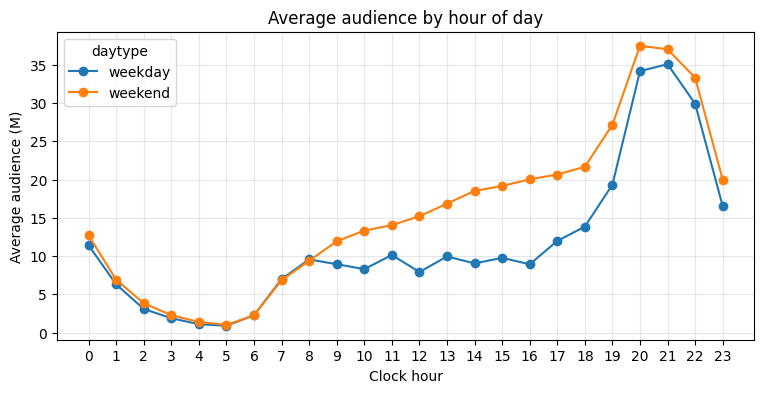

Peak hour, weekdays: 21
Peak hour, weekends: 20


In [35]:
v = viewings[viewings["resp_type"].isin(["R", "L"])].copy().reset_index(drop=True)
v["start_ts"] = pd.to_datetime(v["start_ts"])
v["end_ts"] = pd.to_datetime(v["end_ts"])

first = v["start_ts"].dt.floor("h")
last = (v["end_ts"] - pd.Timedelta(seconds=1)).dt.floor("h")
n = ((last - first) / pd.Timedelta(hours=1)).astype(int) + 1
idx = np.repeat(np.arange(len(v)), n.values)
k = np.arange(len(idx)) - np.repeat(np.cumsum(n.values) - n.values, n.values)

s = v.iloc[idx].reset_index(drop=True)
s["hour_start"] = first.iloc[idx].reset_index(drop=True) + pd.to_timedelta(k, unit="h")

s["minutes"] = (np.minimum(s["end_ts"], s["hour_start"] + pd.Timedelta(hours=1))
                - np.maximum(s["start_ts"], s["hour_start"])).dt.total_seconds() / 60
s["wmin"] = s["minutes"] * s["weight"]

s["hour"] = s["hour_start"].dt.hour
bday = (s["hour_start"] - pd.Timedelta(hours=6)).dt.normalize()
s["daytype"] = np.where(bday.dt.dayofweek < 5, "weekday", "weekend")

days = pd.Series(pd.to_datetime(daily_weights["broadcast_date"].unique()))
n_days = np.where(days.dt.dayofweek < 5, "weekday", "weekend")
n_days = pd.Series(n_days).value_counts()

aud = (s.groupby(["daytype", "hour"])["wmin"].sum()
         .unstack("daytype").reindex(range(24)).fillna(0))
aud = aud / 60 / n_days / 1e6

aud[["weekday", "weekend"]].plot(figsize=(9, 4), marker="o")
plt.xlabel("Clock hour"); plt.ylabel("Average audience (M)")
plt.title("Average audience by hour of day"); plt.xticks(range(24)); plt.grid(alpha=.3)
plt.show()

print("Peak hour, weekdays:", int(aud["weekday"].idxmax()))
print("Peak hour, weekends:", int(aud["weekend"].idxmax()))

**Answer:** The graph showing average viewership by hour clearly illustrates how weekends differ from weekdays. First, the peak viewing hours do not coincide: on weekdays, viewership peaks at 9:00 p.m., while on weekends, the largest number of viewers is observed an hour earlier - at 8:00 p.m. Second, throughout the day-roughly from 8:00 a.m. to 6:00 p.m. - the orange line (weekends) consistently stays above the blue line (weekdays), indicating significantly higher daytime viewer activity on weekends. At the same time, during the morning hours (from 12:00 a.m. to 6:00 a.m.) and late at night (at 11:00 p.m.), viewership levels on weekdays and weekends are nearly identical. Furthermore, although both lines rise sharply after 6:00 p.m., on weekdays this increase is steeper and peaks later; however, after 10:00 p.m., the weekday audience declines more rapidly than on weekends.


## Task 1.3 — Session length

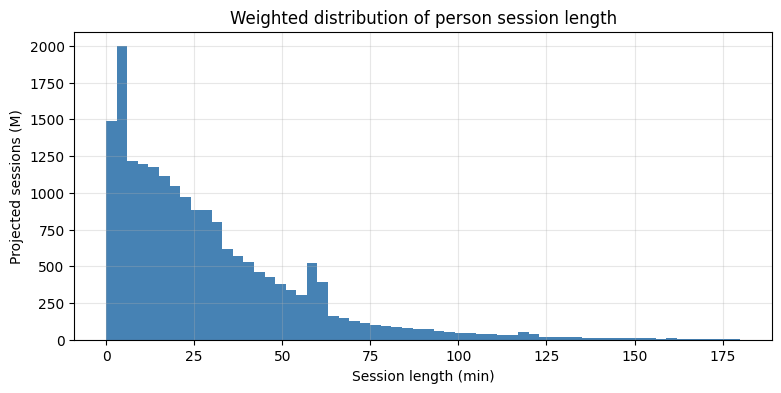

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [36]:
v['duration']=(v['end_ts']-v['start_ts']).dt.total_seconds() / 60

wmean = (v["duration"] * v["weight"]).sum() / v["weight"].sum()

s = v.sort_values("duration")
cum = s["weight"].cumsum()
wmedian = s.loc[cum >= cum.iloc[-1] / 2, "duration"].iloc[0]
plt.figure(figsize=(9, 4))
plt.hist(v["duration"], bins=60, range=(0, 180),
         weights=v["weight"] / 1e6, color="steelblue")
plt.xlabel("Session length (min)")
plt.ylabel("Projected sessions (M)")
plt.title("Weighted distribution of person session length")
plt.grid(alpha=.3)
plt.show()

print("Session length, weighted mean (min):", round(wmean, 1))
print("Session length, weighted median (min):", round(wmedian, 1))

**Answer:** The mean (29.4 minutes) and the median (21.0 minutes) differ due to the asymmetrical shape of the data distribution, which is clearly visible in the histogram. The bulk of the sessions are concentrated in the range up to 25 minutes (forming a peak at the beginning of the graph), but there is a long “tail” on the right-a small number of very long sessions lasting over 100 or even 150 minutes. The median, as the middle value, is resilient to these extreme outliers and shows that a typical, “middle” session lasts 21 minutes. In contrast, the arithmetic mean is sensitive to large numbers: these long sessions “pull” the mean upward, making it significantly larger than the median.

For the client, I would recommend showing the median (21.0 minutes), as it is a more reliable and representative indicator of “typical” user behavior. If you show the client the mean (29.4), it could create the false impression that most users spend nearly half an hour on the platform, when in fact half of all sessions are shorter than 21 minutes. The median provides a clearer understanding of the actual experience of the majority of viewers.


## Task 2 — Program reach curve

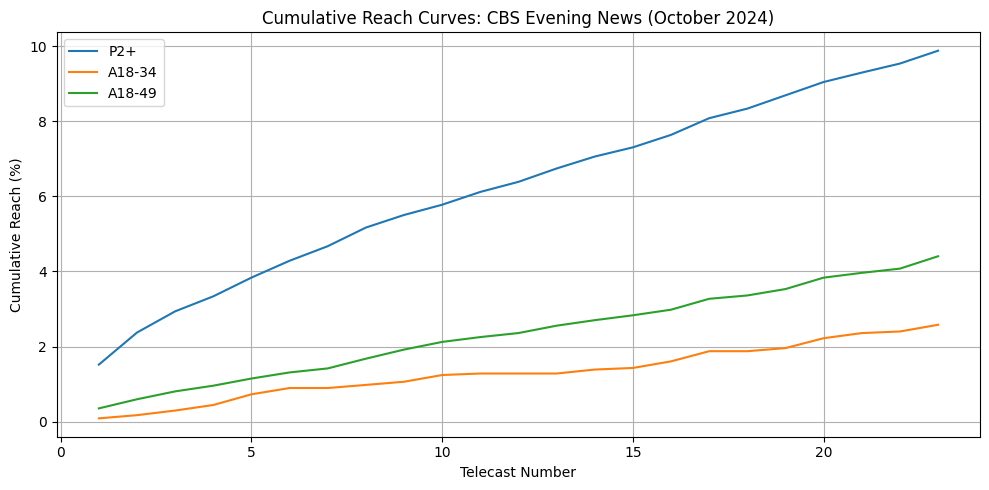

Telecasts of the program: ['CBS Evening News']
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [37]:
age_df = viewer_attributes[viewer_attributes['attr_id'] == 300][['respondent_id', 'value']].rename(columns={'value': 'age'})

persons_info = daily_weights[['respondent_id', 'resp_type']].drop_duplicates().merge(age_df, on='respondent_id', how='left')

monthly_weights = daily_weights.groupby('respondent_id')['weight'].mean().reset_index().rename(columns={'weight': 'monthly_weight'})
persons_info = persons_info.merge(monthly_weights, on='respondent_id', how='left')

p2_info = persons_info[(persons_info['resp_type'].isin(['R', 'L'])) & (persons_info['age'] >= 2)]
a18_34_info = persons_info[(persons_info['resp_type'].isin(['R', 'L'])) & (persons_info['age'] >= 18) & (persons_info['age'] <= 34)]
a18_49_info = persons_info[(persons_info['resp_type'].isin(['R', 'L'])) & (persons_info['age'] >= 18) & (persons_info['age'] <= 49)]

p2_ids = set(p2_info['respondent_id'])
a18_34_ids = set(a18_34_info['respondent_id'])
a18_49_ids = set(a18_49_info['respondent_id'])

daily_in_tab = daily_weights.merge(persons_info[['respondent_id', 'age']], on='respondent_id', how='left')
daily_hh_denom = daily_in_tab[daily_in_tab['resp_type'] == 'H'].groupby('broadcast_date')['weight'].sum()
daily_p2_denom = daily_in_tab[(daily_in_tab['resp_type'].isin(['R', 'L'])) & (daily_in_tab['age'] >= 2)].groupby('broadcast_date')['weight'].sum()

denom_reach_p2 = p2_info['monthly_weight'].sum()
denom_reach_a18_34 = a18_34_info['monthly_weight'].sum()
denom_reach_a18_49 = a18_49_info['monthly_weight'].sum()

cbs_news = programs[
    (programs['network_code'] == 'CBS') &
    (programs['program_name'].str.contains('CBS Evening News', case=False, na=False)) &
    (pd.to_datetime(programs['broadcast_date']).dt.month == 10) &
    (pd.to_datetime(programs['broadcast_date']).dt.dayofweek < 5)
].sort_values('start_ts').reset_index(drop=True)

cbs_viewings = viewings[viewings['network_code'] == 'CBS'].copy()

results = []
seen_p2, seen_a18_34, seen_a18_49 = set(), set(), set()
reach_p2_list, reach_a18_34_list, reach_a18_49_list = [], [], []

for idx, telecast in cbs_news.iterrows():
    t_start, t_end = telecast['start_ts'], telecast['end_ts']
    b_date = telecast['broadcast_date']

    cand = cbs_viewings[(cbs_viewings['start_ts'] < t_end) & (cbs_viewings['end_ts'] > t_start)].copy()

    overlap_start = np.maximum(cand['start_ts'], t_start)
    overlap_end = np.minimum(cand['end_ts'], t_end)
    cand['dur_min'] = (overlap_end - overlap_start).dt.total_seconds() / 60.0

    user_dur = cand.groupby('respondent_id')['dur_min'].sum().reset_index()
    valid_respondents = set(user_dur[user_dur['dur_min'] >= 1.0]['respondent_id'])

    day_weights = daily_weights[daily_weights['broadcast_date'] == b_date]
    valid_weights = day_weights[day_weights['respondent_id'].isin(valid_respondents)]

    hh_weight_sum = valid_weights[valid_weights['resp_type'] == 'H']['weight'].sum()
    hh_rating = (hh_weight_sum / daily_hh_denom.get(b_date, np.nan)) * 100

    p2_weights = valid_weights[(valid_weights['resp_type'].isin(['R', 'L'])) & (valid_weights['respondent_id'].isin(p2_ids))]
    p2_weight_sum = p2_weights['weight'].sum()
    p2_rating = (p2_weight_sum / daily_p2_denom.get(b_date, np.nan)) * 100

    projected_audience_m = p2_weight_sum / 1e6

    results.append({
        'telecast_id': telecast['telecast_id'],
        'broadcast_date': b_date,
        'hh_rating': hh_rating,
        'p2plus_rating': p2_rating,
        'projected_audience_m': projected_audience_m
    })

    seen_p2.update(valid_respondents & p2_ids)
    seen_a18_34.update(valid_respondents & a18_34_ids)
    seen_a18_49.update(valid_respondents & a18_49_ids)

    reach_p2_list.append((p2_info[p2_info['respondent_id'].isin(seen_p2)]['monthly_weight'].sum() / denom_reach_p2) * 100)
    reach_a18_34_list.append((a18_34_info[a18_34_info['respondent_id'].isin(seen_a18_34)]['monthly_weight'].sum() / denom_reach_a18_34) * 100)
    reach_a18_49_list.append((a18_49_info[a18_49_info['respondent_id'].isin(seen_a18_49)]['monthly_weight'].sum() / denom_reach_a18_49) * 100)

df_results = pd.DataFrame(results)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(df_results) + 1), reach_p2_list, label='P2+')
plt.plot(range(1, len(df_results) + 1), reach_a18_34_list, label='A18-34')
plt.plot(range(1, len(df_results) + 1), reach_a18_49_list, label='A18-49')
plt.title('Cumulative Reach Curves: CBS Evening News (October 2024)')
plt.xlabel('Telecast Number')
plt.ylabel('Cumulative Reach (%)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print("Telecasts of the program:", cbs_news['program_name'].unique())
print("Average household rating (%):", round(df_results['hh_rating'].mean(), 1))
print("Average P2+ rating (%):", round(df_results['p2plus_rating'].mean(), 1))
print("Average projected audience (M):", round(df_results['projected_audience_m'].mean(), 2))
print("Final reach P2+ (%):", round(reach_p2_list[-1], 1))
print("Final reach A18-34 (%):", round(reach_a18_34_list[-1], 1))
print("Final reach A18-49 (%):", round(reach_a18_49_list[-1], 1))

**Answer:** This graph shows the cumulative reach curves for the “CBS Evening News” program for October 2024, illustrating the percentage of the population that was reached at least once during consecutive broadcasts (Telecast Number).

When comparing reach to ratings, it is important to note that ratings measure the average audience per broadcast, while reach shows the total number of unique viewers who saw the content at least once during a specific period. The graph shows three demographic groups: P2+ (all viewers aged 2 and older, blue line), A18-49 (adults aged 18–49, green line), and A18-34 (young adults aged 18–34, orange line).

The broad P2+ audience demonstrates the best reach: its cumulative curve rises the fastest and reaches a final figure of 9.9%. This is because this group is the largest and includes all age categories, so people of all ages watch the news, ensuring maximum total reach.

The A18-49 group ranks second in reach with a final figure of 4.4%, while the youngest audience, A18-34, has the lowest reach at just 2.6%. This difference is due to two factors. First, the population sizes of the groups differ: there are significantly more people aged 18–49 than 18–34. Second, and most importantly, there is a difference in media consumption: young people (18–34) watch traditional evening news on television much less frequently, preferring streaming platforms and social media. At the same time, the older audience (which is included in the P2+ group but not in the A18-34 group) is the primary and most loyal viewership base for evening news programs, which explains the P2+ group’s dominance in this chart.

## Task 3 — Program frequency

In [38]:
yr = programs[
    (programs['network_code'] == 'CBS') &
    (programs['program_name'] == 'The Young and the Restless')
].sort_values('start_ts').reset_index(drop=True)

counter = Counter()
for _, t in yr.iterrows():
    t_start, t_end = t['start_ts'], t['end_ts']

    cand = cbs_viewings[(cbs_viewings['start_ts'] < t_end) & (cbs_viewings['end_ts'] > t_start)].copy()
    ov_start = np.maximum(cand['start_ts'], t_start)
    ov_end = np.minimum(cand['end_ts'], t_end)
    cand['dur_min'] = (ov_end - ov_start).dt.total_seconds() / 60

    dur = cand.groupby('respondent_id')['dur_min'].sum()
    watchers = set(dur[dur >= 1.0].index) & p2_ids
    counter.update(watchers)

freq_df = pd.DataFrame({'respondent_id': list(counter.keys()),
                        'freq': list(counter.values())})
freq_df = freq_df.merge(monthly_weights, on='respondent_id', how='left')
w = freq_df['monthly_weight']
f = freq_df['freq']

def weighted_quantile(values, weights, q):
    order = np.argsort(values.values)
    v = values.values[order]
    cw = np.cumsum(weights.values[order])
    return v[np.searchsorted(cw, q * cw[-1])]

viewers_m = w.sum() / 10**6
avg_freq = np.average(f, weights=w)
med_freq = weighted_quantile(f, w, 0.5)

p80 = weighted_quantile(f, w, 0.8)
loyal = f >= p80
share_views = (f[loyal] * w[loyal]).sum() / (f * w).sum()
dist = freq_df.groupby('freq')['monthly_weight'].sum() / 10**6

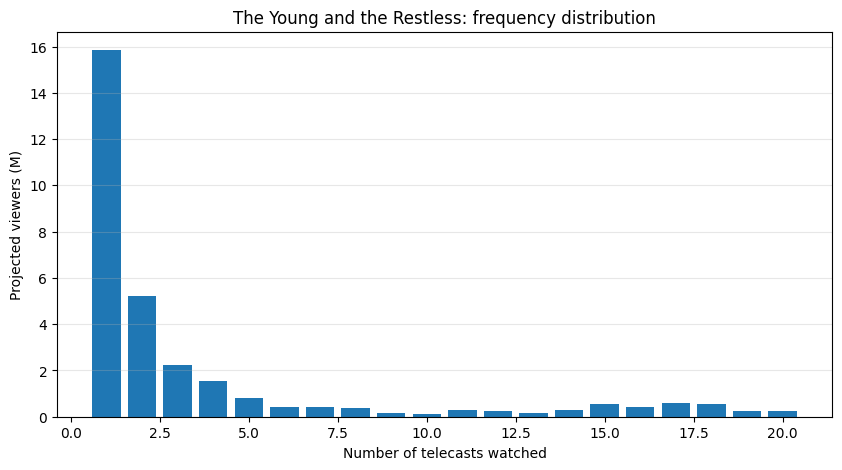

Projected viewers (M): 30.8
Average frequency (weighted): 3.63
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704
Projected viewers (M): Ellipsis
Average frequency (weighted): Ellipsis
Median frequency (weighted): Ellipsis
Share of views from the most loyal viewers: Ellipsis


In [39]:
plt.figure(figsize=(10, 5))
plt.bar(dist.index, dist.values)
plt.xlabel('Number of telecasts watched')
plt.ylabel('Projected viewers (M)')
plt.title('The Young and the Restless: frequency distribution')
plt.grid(axis='y', alpha=0.3)
plt.show()
print("Projected viewers (M):", round(viewers_m, 2))
print("Average frequency (weighted):", round(avg_freq, 2))
print("Median frequency (weighted):", round(med_freq, 2))
print("Share of views from the most loyal viewers:", round(share_views, 3))
print("Projected viewers (M):", ...)
print("Average frequency (weighted):", ...)
print("Median frequency (weighted):", ...)
print("Share of views from the most loyal viewers:", ...)

**Answer:** No, the mean frequency is not a fair or representative summary of this distribution.

Although the weighted average frequency is 3.63, the histogram clearly shows that the distribution is extremely asymmetric (right-skewed). The vast majority of viewers (over 15 million) watched only one broadcast, as confirmed by the median frequency, which is 1.
The mean is artificially inflated by a small but very dedicated group of loyal fans (those who watch 10, 15, or more episodes). As a result, the arithmetic mean creates the false impression that the typical viewer watches the show nearly 4 times, whereas in reality, half of the audience limits themselves to a single viewing. To describe typical behavior, it is much better to use the median (1) or even the mode here, and the mean should only be mentioned as an indicator of the total number of views generated by a small core of loyal fans.

## Task 4 — Networks by age and gender

In [40]:
sex = viewer_attributes[viewer_attributes['attr_id'].isin([201, 202])].copy()
sex['sex'] = sex['attr_id'].map({201: 'M', 202: 'W'})
sex = sex[['respondent_id', 'sex']].drop_duplicates('respondent_id')

age_df = (viewer_attributes[viewer_attributes['attr_id'] == 300]
          [['respondent_id', 'value']].rename(columns={'value': 'age'}))

v = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
v['minutes'] = (v['end_ts'] - v['start_ts']).dt.total_seconds() / 60
v = v.merge(sex, on='respondent_id', how='left').merge(age_df, on='respondent_id', how='left')
v = v.dropna(subset=['age'])
v['proj'] = v['minutes'] * v['weight']

v['band'] = pd.cut(v['age'], bins=[18, 35, 55, 200], right=False, labels=['18-34', '35-54', '55+'])
a = v[v['band'].notna() & v['sex'].notna()].copy()
a['aud'] = a['sex'] + a['band'].astype(str)

g = a.groupby(['aud', 'network_code'])['proj'].sum() / 10**6
for aud in ['M18-34', 'W18-34', 'M35-54', 'W35-54', 'M55+', 'W55+']:
    print(f"\nTop 5 networks: {aud} (M projected minutes)")
    display(g[aud].nlargest(5).round(2))

young = v['age'].between(18, 34)
share_w = v[young].groupby('network_code')['proj'].sum() / v.groupby('network_code')['proj'].sum()
share_raw = v[young].groupby('network_code')['minutes'].sum() / v.groupby('network_code')['minutes'].sum()
share = pd.DataFrame({'weighted': share_w, 'raw': share_raw}).sort_values('weighted')
display(share.round(3))

print("Youngest network:", share['weighted'].idxmax())
print("Oldest network:", share['weighted'].idxmin())



Top 5 networks: M18-34 (M projected minutes)


,proj
network_code,
FOX,4386.65
NBC,3910.39
CBS,3044.35
ABC,3010.78
FX,1473.96



Top 5 networks: W18-34 (M projected minutes)


,proj
network_code,
FOX,4574.44
NBC,4527.59
ABC,3504.86
CBS,2811.22
FX,1383.47



Top 5 networks: M35-54 (M projected minutes)


...

,proj
network_code,
CBS,38274.03
NBC,34267.41
FOX,30878.51
ABC,30793.34
FNC,27903.71



Top 5 networks: W55+ (M projected minutes)


,proj
network_code,
CBS,47120.32
NBC,41391.87
ABC,38840.01
FOX,36914.72
FNC,31450.73


,weighted,raw
network_code,,
FNC,0.018,0.017
HIST,0.048,0.044
CBS,0.051,0.050
HGTV,0.058,0.052
ABC,0.064,0.060
NBC,0.073,0.068
FOOD,0.078,0.071
FOX,0.082,0.075
BRAVO,0.148,0.127


Youngest network: FX
Oldest network: FNC


**Answer:** weighted vs raw.

A comparison of the weighted and raw shares of the young audience (18–34) for each TV channel shows that, although the overall ratings of the networks remain unchanged, weighting significantly affects the accuracy of the estimates. The weighted approach accounts for the representativeness of each respondent in the panel—that is, how many actual people in the general population they represent—while the unweighted (raw) approach simply sums up viewing minutes without taking these weights into account, which can lead to skewed results if the panel is disproportionately skewed toward certain age groups.

In this analysis, FX turned out to be the “youngest” TV network (weighted share 0.266, unweighted 0.232), and FNC the “oldest” (weighted 0.018, unweighted 0.017). For all networks without exception, the weighted share was higher than the unweighted share. This means that young viewers (18–34) carry greater weight in the panel than their actual proportion in the sample: if we had used unweighted data, we would have underestimated the young audience’s actual contribution to viewership of these channels. Thus, to obtain accurate and representative results regarding the behavior of young people, it is necessary to use a weighted approach, as it compensates for sample disparities and ensures that the actual structure of the population is reflected.